# Income & Spending Survey Analysis
**Author:** Brittney Everson  
**Project:** Healthcare Product Launch – Participant Income & Spending Survey

This notebook loads the CSV exported from MongoDB (`export_to_csv.py`) and produces the client charts:

1. Which ages have the highest income
2. Gender distribution across spending categories

Every chart is exported as a PNG to the `charts/` folder for the client PowerPoint.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA_PATH = os.path.join("..", "data", "survey_data.csv")
CHART_DIR = os.path.join("..", "charts")
os.makedirs(CHART_DIR, exist_ok=True)

CATEGORIES = ["utilities", "entertainment", "school_fees", "shopping", "healthcare"]
LABELS = {"utilities": "Utilities", "entertainment": "Entertainment",
          "school_fees": "School Fees", "shopping": "Shopping", "healthcare": "Healthcare"}
GENDER_ORDER = ["Female", "Male", "Non-binary", "Prefer not to say"]
GENDER_COLORS = {"Female": "#2C6E63", "Male": "#E0A33B", "Non-binary": "#7A5C99", "Prefer not to say": "#9AA5A8"}
PRIMARY, HIGHLIGHT, GREY = "#2C6E63", "#E0A33B", "#C9D3D1"

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 14})

def save(fig, name):
    path = os.path.join(CHART_DIR, name)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("Saved", path)

## 1. Load the CSV

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"{len(df)} participants loaded")
df.head()

200 participants loaded


,user_id,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,total_expenses,spending_ratio,submitted_at
0,6ae025beafb6dad8fc032639,57,Male,7370.0,698.57,566.62,0.0,865.81,687.54,2818.54,0.3824,2026-10-13T06:58:02.796000
1,6ae025beafb6dad8fc032662,75,Female,4410.0,230.22,243.97,0.0,553.95,468.84,1496.98,0.3395,2026-10-13T09:39:02.797000
2,6ae025beafb6dad8fc032672,57,Male,9460.0,805.43,0.00,0.0,1130.01,681.66,2617.10,0.2766,2026-10-13T09:53:02.797000
3,6ae025beafb6dad8fc0326b3,44,Male,9910.0,885.85,0.00,0.0,1052.15,484.46,2422.46,0.2444,2026-10-13T09:54:02.797000
4,6ae025beafb6dad8fc032631,62,Female,9600.0,1040.02,437.75,0.0,890.42,0.00,2368.19,0.2467,2026-10-13T10:50:02.796000


In [3]:
# Quick data checks
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().any() else "None")
df[["age", "total_income", "total_expenses"]].describe().round(1)

Missing values per column:
None


,age,total_income,total_expenses
count,200.0,200.0,200.0
mean,47.8,7218.2,2045.3
std,16.3,2689.0,1001.5
min,18.0,1200.0,0.0
25%,34.8,5307.5,1217.0
50%,48.5,7600.0,2048.5
75%,61.2,9322.5,2716.8
max,75.0,12190.0,4735.7


In [4]:
# Gender breakdown of the sample
df["gender"].value_counts().reindex(GENDER_ORDER).fillna(0).astype(int)

gender
Female               105
Male                  77
Non-binary            13
Prefer not to say      5
Name: count, dtype: int64

## 2. Which ages have the highest income?

Two views:
- **Chart 1** – the 10 individual ages with the highest average income.
- **Chart 2** – average income by age band. Single ages can have only a few people each, so the band view is the more reliable read for the client.

In [5]:
by_age = (df.groupby("age")["total_income"]
            .agg(avg_income="mean", participants="count")
            .sort_values("avg_income", ascending=False))
top10 = by_age.head(10)
top10.round(0)

,avg_income,participants
age,,
52,11235.0,2
48,11050.0,1
43,10960.0,1
54,10490.0,4
56,10458.0,4
39,10320.0,1
50,9745.0,2
53,9673.0,6
63,9645.0,2


Saved ../charts/01_top_ages_by_income.png


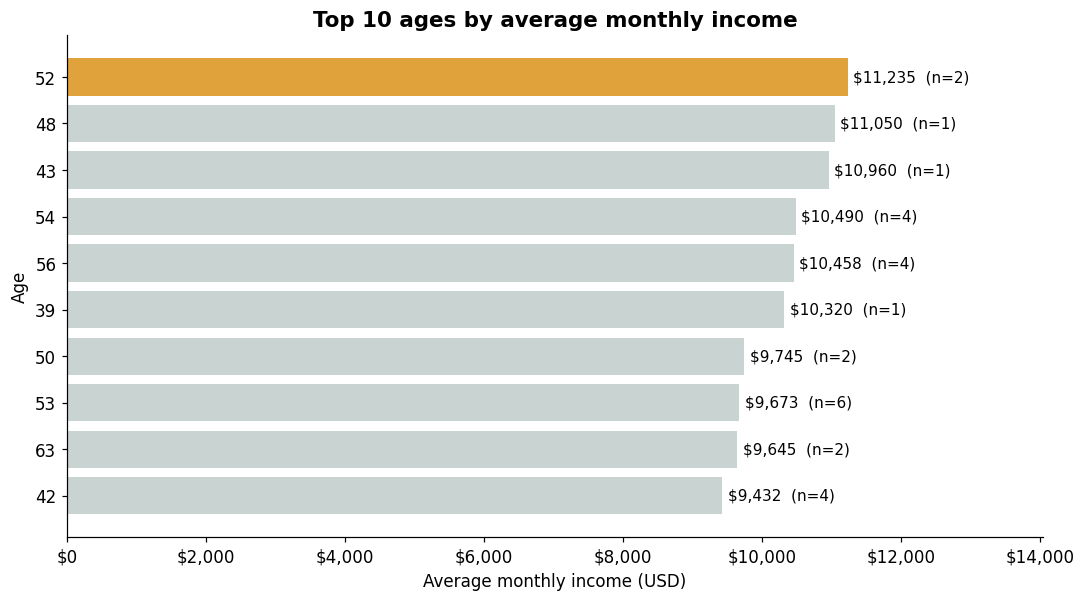

In [6]:
plot_data = top10.sort_values("avg_income")
colors = [GREY] * (len(plot_data) - 1) + [HIGHLIGHT]
fig, ax = plt.subplots(figsize=(10, 5.6))
bars = ax.barh(plot_data.index.astype(str), plot_data["avg_income"], color=colors)
for bar, (age, row) in zip(bars, plot_data.iterrows()):
    ax.text(bar.get_width() + 80, bar.get_y() + bar.get_height() / 2,
            f"${row.avg_income:,.0f}  (n={int(row.participants)})", va="center", fontsize=10)
ax.set_title("Top 10 ages by average monthly income")
ax.set_xlabel("Average monthly income (USD)")
ax.set_ylabel("Age")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(0, plot_data["avg_income"].max() * 1.25)
plt.tight_layout()
save(fig, "01_top_ages_by_income.png")
plt.show()

In [7]:
bins = [17, 24, 34, 44, 54, 64, 100]
band_labels = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
df["age_band"] = pd.cut(df["age"], bins=bins, labels=band_labels)
by_band = (df.groupby("age_band", observed=False)["total_income"]
             .agg(avg_income="mean", participants="count"))
by_band.round(0)

,avg_income,participants
age_band,,
18-24,2802.0,22
25-34,6018.0,28
35-44,8755.0,35
45-54,9523.0,38
55-64,8611.0,35
65+,5805.0,42


Saved ../charts/02_income_by_age_band.png


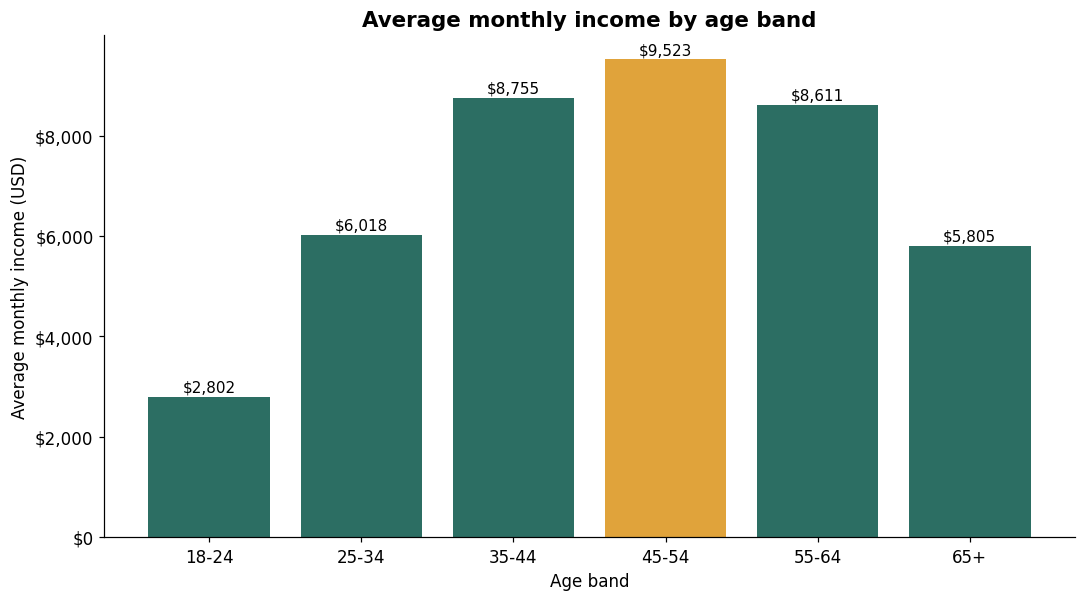

Highest-earning age band: 45-54 ($9,523/month)


In [8]:
top_band = by_band["avg_income"].idxmax()
colors = [HIGHLIGHT if b == top_band else PRIMARY for b in by_band.index]
fig, ax = plt.subplots(figsize=(10, 5.6))
bars = ax.bar(by_band.index.astype(str), by_band["avg_income"], color=colors)
for bar, val in zip(bars, by_band["avg_income"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100, f"${val:,.0f}",
            ha="center", fontsize=10)
ax.set_title("Average monthly income by age band")
ax.set_xlabel("Age band")
ax.set_ylabel("Average monthly income (USD)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
save(fig, "02_income_by_age_band.png")
plt.show()
print(f"Highest-earning age band: {top_band} (${by_band.loc[top_band, 'avg_income']:,.0f}/month)")

## 3. Gender distribution across spending categories

- **Chart 3** – how many participants of each gender spend in each category (a ticked box with an amount above 0).
- **Chart 4** – average monthly spend per category by gender, among people who spend in that category.

In [9]:
genders = [g for g in GENDER_ORDER if g in df["gender"].unique()]
counts = pd.DataFrame({LABELS[c]: df[df[c] > 0]["gender"].value_counts() for c in CATEGORIES}).T
counts = counts.reindex(columns=genders).fillna(0).astype(int)
counts

gender,Female,Male,Non-binary,Prefer not to say
Utilities,101,72,13,5
Entertainment,81,53,11,4
School Fees,23,14,3,1
Shopping,95,73,13,5
Healthcare,77,51,12,4


Saved ../charts/03_gender_by_category_count.png


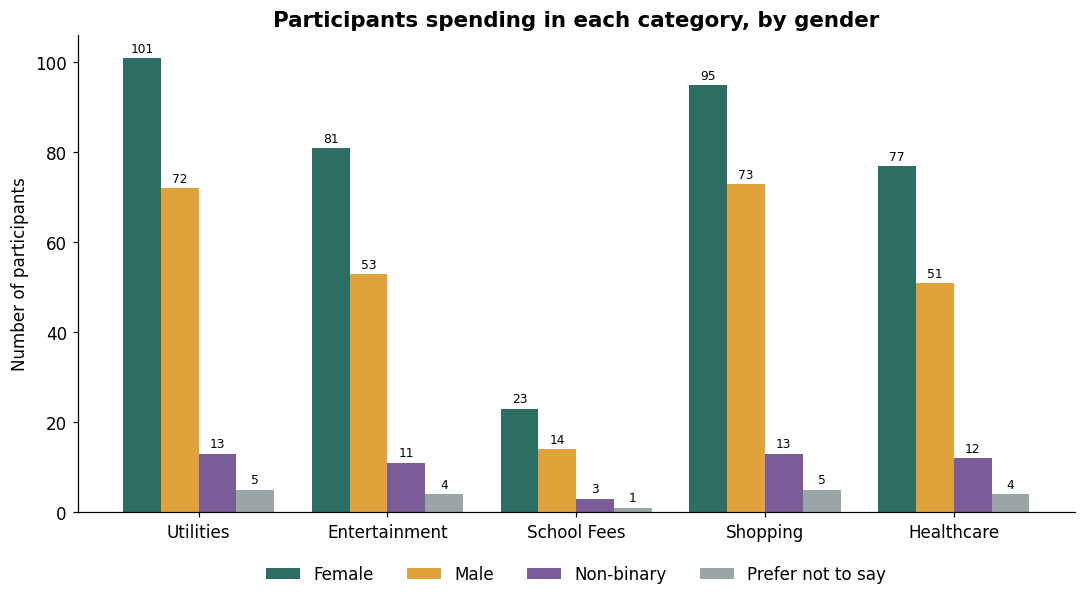

In [10]:
import numpy as np
x = np.arange(len(counts.index))
width = 0.8 / len(genders)
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, g in enumerate(genders):
    bars = ax.bar(x + i * width - 0.4 + width / 2, counts[g], width, label=g, color=GENDER_COLORS[g])
    ax.bar_label(bars, fontsize=8, padding=2)
ax.set_xticks(x, counts.index)
ax.set_title("Participants spending in each category, by gender")
ax.set_ylabel("Number of participants")
ax.legend(frameon=False, ncol=len(genders), loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
save(fig, "03_gender_by_category_count.png")
plt.show()

In [11]:
avg_spend = pd.DataFrame({
    LABELS[c]: df[df[c] > 0].groupby("gender")[c].mean() for c in CATEGORIES
}).T.reindex(columns=genders)
avg_spend.round(0)

gender,Female,Male,Non-binary,Prefer not to say
Utilities,549.0,580.0,669.0,713.0
Entertainment,357.0,436.0,380.0,429.0
School Fees,701.0,861.0,773.0,1272.0
Shopping,677.0,662.0,738.0,842.0
Healthcare,612.0,533.0,564.0,591.0


Saved ../charts/04_gender_avg_spend_by_category.png


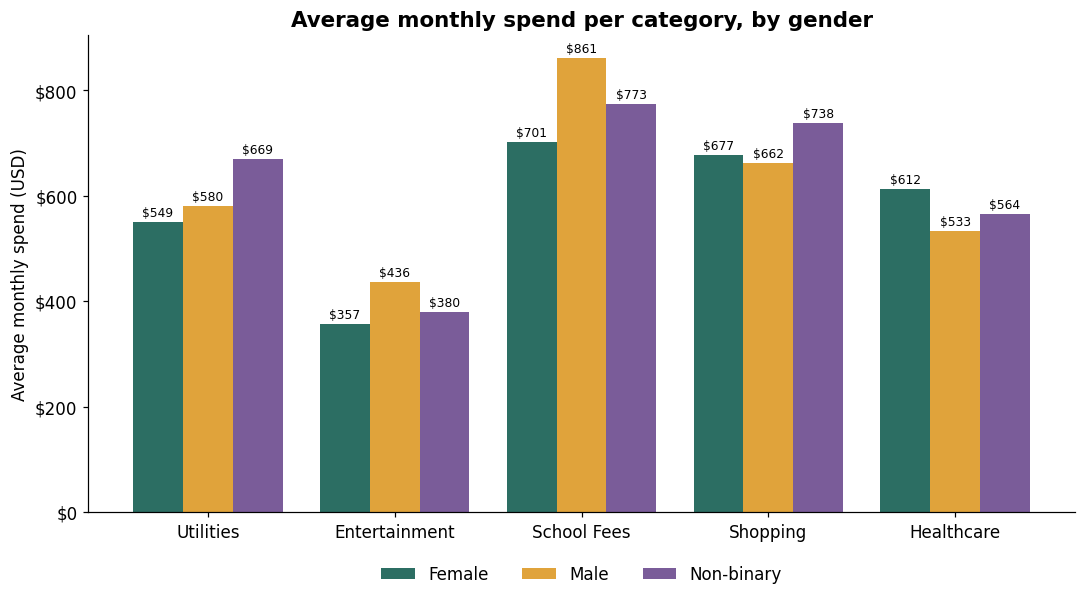

Left out of chart 4 (fewer than 10 people): ['Prefer not to say']


In [12]:
# Groups under 10 people are too small to compare averages fairly, so they are left out of chart 4.
group_sizes = df["gender"].value_counts()
main_genders = [g for g in genders if group_sizes.get(g, 0) >= 10]
fig, ax = plt.subplots(figsize=(10, 5.6))
width = 0.8 / len(main_genders)
for i, g in enumerate(main_genders):
    bars = ax.bar(x + i * width - 0.4 + width / 2, avg_spend[g], width, label=g, color=GENDER_COLORS[g])
    ax.bar_label(bars, labels=[f"${v:,.0f}" for v in avg_spend[g]], fontsize=8, padding=2)
ax.set_xticks(x, avg_spend.index)
ax.set_title("Average monthly spend per category, by gender")
ax.set_ylabel("Average monthly spend (USD)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.legend(frameon=False, ncol=len(main_genders), loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
save(fig, "04_gender_avg_spend_by_category.png")
plt.show()
print("Left out of chart 4 (fewer than 10 people):", [g for g in genders if g not in main_genders] or "none")

## 4. Save summary tables for the client deck

In [13]:
top10.round(2).to_csv(os.path.join(CHART_DIR, "table_top_ages_by_income.csv"))
by_band.round(2).to_csv(os.path.join(CHART_DIR, "table_income_by_age_band.csv"))
counts.to_csv(os.path.join(CHART_DIR, "table_gender_by_category_count.csv"))
avg_spend.round(2).to_csv(os.path.join(CHART_DIR, "table_gender_avg_spend.csv"))
sorted(os.listdir(CHART_DIR))

['01_top_ages_by_income.png',
 '02_income_by_age_band.png',
 '03_gender_by_category_count.png',
 '04_gender_avg_spend_by_category.png',
 'table_gender_avg_spend.csv',
 'table_gender_by_category_count.csv',
 'table_income_by_age_band.csv',
 'table_top_ages_by_income.csv']

## 5. Key takeaways
- Income climbs with age and peaks in the middle-age bands (see Chart 2). This is the core buyer group for a paid healthcare product.
- Healthcare spending is common across all genders (Chart 3). Female participants show a higher average healthcare spend (Chart 4).
- Non-binary and "Prefer not to say" groups are small in this sample. Collect more responses before drawing conclusions about them.

*Note: until the live survey collects enough real responses, this analysis runs on sample data created by `seed_sample_data.py`. Re-run `export_to_csv.py` and this notebook to refresh every chart.*